In [1]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

In [2]:
G.add_nodes_from(["S0", "S1", "S2", "S3", "S4", "S5", "S6", "S7"])

# Algoritimo de Dijkstra:

In [3]:

G = nx.Graph()
edges = [
('S0', 'S1', 10), 
('S0', 'S2', 21),
('S1', 'S2', 10), 
('S1', 'S3', 12), 
('S2', 'S4', 15), 
('S2', 'S5', 14), 
('S3', 'S4', 7 ), 
('S3', 'S6', 13), 
('S4', 'S5', 8 ), 
('S4', 'S7', 17),
('S5', 'S7', 24),
('S6', 'S7', 10),
('S1', 'S4', 21),]
G.add_weighted_edges_from(edges)
distances = nx.single_source_dijkstra_path_length(G, source='S0')
print("Shortest distances from S0:", distances)

Shortest distances from S0: {'S0': 0, 'S1': 10, 'S2': 20, 'S3': 22, 'S4': 29, 'S5': 34, 'S6': 35, 'S7': 45}


# Algoritmo de Prim

In [4]:
grafo_prim = nx.Graph()
grafo_prim.add_weighted_edges_from(edges)
mst = nx.minimum_spanning_tree(grafo_prim, algorithm="prim", weight="weight")

arestas_prim = sorted(
    (min(u, v), max(u, v), dados["weight"])
    for u, v, dados in mst.edges(data=True)
)

print("Resultado do Prim:")
for u, v, peso in arestas_prim:
    print(f"{u} — {v}: {peso} km")

peso_total = mst.size(weight="weight")
print(f"\nPeso total: {peso_total:g} km")
print(f"Vértices: {mst.number_of_nodes()} | Arestas: {mst.number_of_edges()}")

Resultado do Prim:
S0 — S1: 10 km
S1 — S2: 10 km
S1 — S3: 12 km
S3 — S4: 7 km
S3 — S6: 13 km
S4 — S5: 8 km
S6 — S7: 10 km

Peso total: 70 km
Vértices: 8 | Arestas: 7


# Matriz de adjacência ponderada

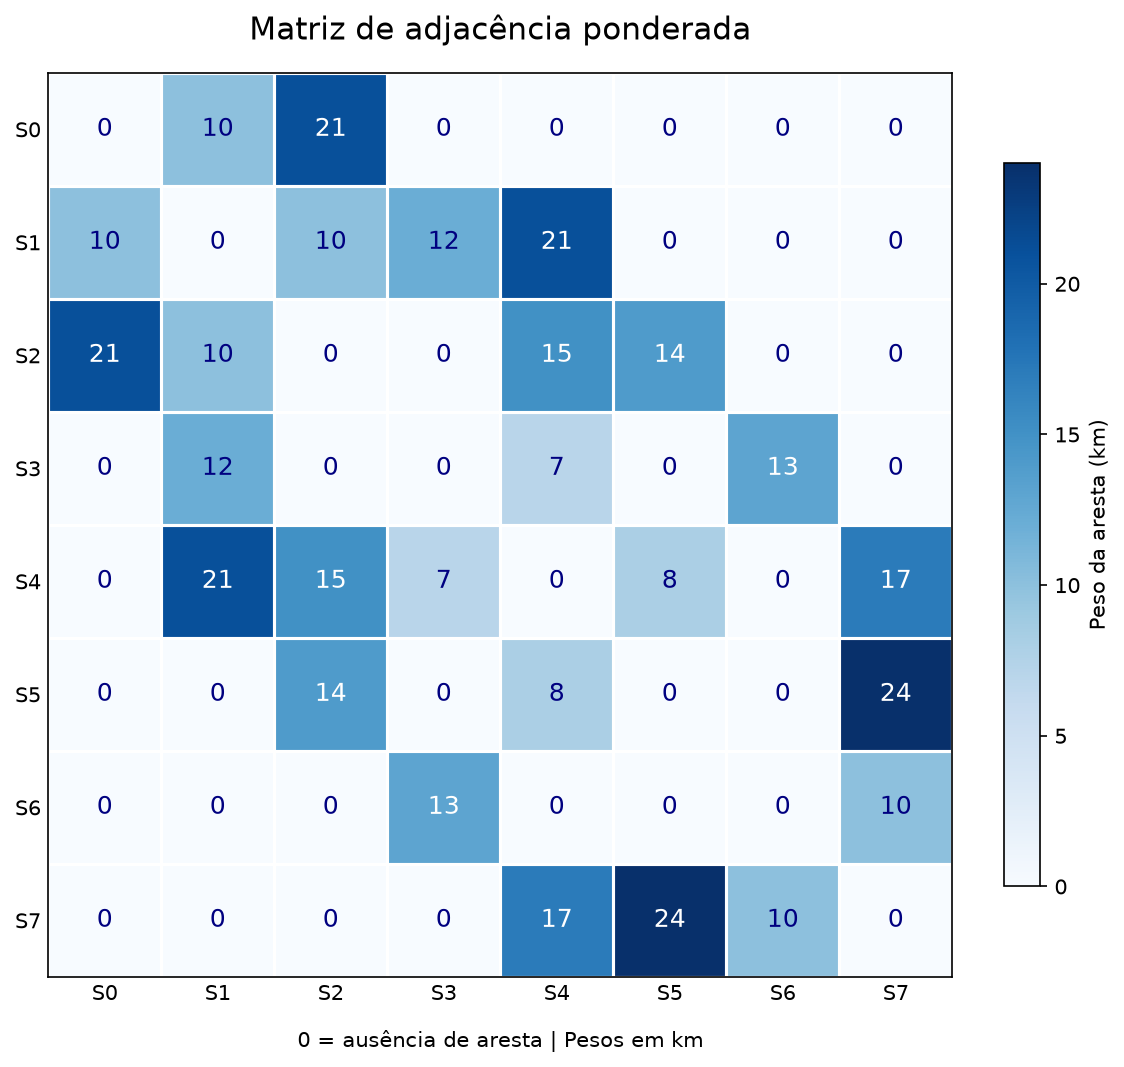

In [5]:
grafo_visualizacao = nx.Graph()
grafo_visualizacao.add_weighted_edges_from(edges)
vertices = [f"S{i}" for i in range(8)]
matriz_adjacencia = nx.to_numpy_array(
    grafo_visualizacao, nodelist=vertices, weight="weight", dtype=int
)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
imagem = ax.imshow(matriz_adjacencia, cmap="Blues", vmin=0, vmax=24)
ax.set_xticks(range(8), labels=vertices)
ax.set_yticks(range(8), labels=vertices)
ax.set_title("Matriz de adjacência ponderada", fontsize=15, pad=16)
ax.set_xlabel("0 = ausência de aresta | Pesos em km", labelpad=12)

for i in range(8):
    for j in range(8):
        peso = matriz_adjacencia[i, j]
        cor = "white" if peso >= 13 else "navy"
        ax.text(j, i, str(peso), ha="center", va="center", color=cor, fontsize=12)

ax.set_xticks([i - 0.5 for i in range(9)], minor=True)
ax.set_yticks([i - 0.5 for i in range(9)], minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="both", length=0)
fig.colorbar(imagem, ax=ax, label="Peso da aresta (km)", shrink=0.8)
plt.show()

# Etapa 3, exercício 2: Grafo da rede
Essa docs do drawing do networkx ajudou a fazer:
[Documentação: desenho de grafos](https://networkx.org/documentation/stable/reference/drawing.html)

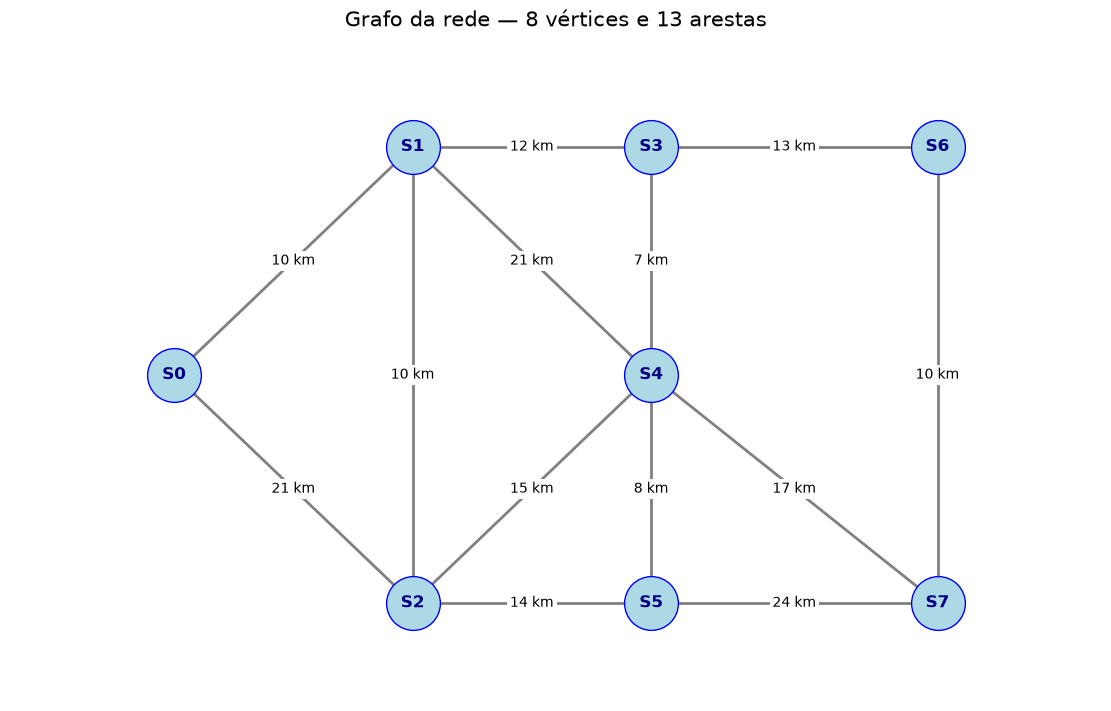

In [13]:
grafo_visualizacao = nx.Graph()
grafo_visualizacao.add_weighted_edges_from(edges)

# Posições fixas para facilitar a leitura das conexões.
posicoes = {
    "S0": (0, 1.5),
    "S1": (1, 2.7),
    "S2": (1, 0.3),
    "S3": (2, 2.7),
    "S4": (2, 1.5),
    "S5": (2, 0.3),
    "S6": (3.2, 2.7),
    "S7": (3.2, 0.3),
}
rotulos_pesos = {
    (u, v): f"{dados['weight']} km"
    for u, v, dados in grafo_visualizacao.edges(data=True)
}

fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
nx.draw_networkx(
    grafo_visualizacao, pos=posicoes, ax=ax,
    node_color="lightblue", edgecolors="blue", node_size=1500,
    font_size=12, font_weight="bold", font_color="navy",
    edge_color="gray", width=2,
)
nx.draw_networkx_edge_labels(
    grafo_visualizacao, pos=posicoes, edge_labels=rotulos_pesos,
    ax=ax, font_size=10, rotate=False,
    bbox=dict(facecolor="white", edgecolor="none", pad=2),
)
ax.set_title("Grafo da rede — 8 vértices e 13 arestas", fontsize=15, pad=16)
ax.margins(0.15)
ax.set_axis_off()
plt.show()